# Data Steward: retrieval, typed tools, and measured agent reliability

**Question:** Which allocation of model decisions and deterministic execution reliably investigates sensor-data incidents?

The system combines a versioned dataset catalog, TF-IDF plus lexical reciprocal-rank retrieval, allowlisted typed tools, and SQLite provenance. [Project guide](../projects/02-data-steward/README.md)

## How to run
Run all cells from the repository root or this directory. Install the notebook extra with `uv pip install -e '.[notebooks]'` and select that Python environment. The report sections need only committed JSON measurements. They do not need checkpoints, API keys, downloads, or Apple hardware. Edge Sense and Edge Pilot also have an optional local inference section that needs generated checkpoints and validation arrays. Saved study outputs and fresh local measurements are labeled separately.

## What this project is for

Suppose activity predictions suddenly get worse. Before retraining a network, a developer should check whether the incoming sensor data is still valid. Maybe the gyroscope has become constant, a file came from the wrong dataset version, or a preprocessing step changed.

Data Steward turns a short incident request into a sequence of checks. It does not edit arbitrary files or execute model-written shell commands. It chooses from a fixed set of tools that expose the dataset catalog, retrieve runbook passages, audit sensor arrays, and simulate specific faults. Each call is recorded so a developer can inspect the investigation afterward.

## What retrieval and typed tools mean here

A **runbook** is a short document describing how to investigate a known problem. Retrieval searches those documents for passages related to the request. This project combines TF-IDF word matching with another lexical ranking, then merges their ranks. It can run locally without a vector database or a paid API.

A **typed tool** has a defined name and arguments. For example, a simulation must identify a supported corruption and data split. Valid arguments keep the program callable; they do not prove the chosen action makes sense. Looking up the right missing-sensor runbook and then simulating the wrong fault is still a failed investigation.

The catalog stores where the data came from and its checksums. SQLite stores execution records. This is the data-management part: an answer can be traced back to a dataset version and a sequence of operations.

## Why compare several planners

The policy version uses rules written in code. It is a useful baseline because its decisions are predictable. The local-model versions ask Qwen to make some of those decisions. The schema-only version restricts the answer format; workflow guards add ordering and evidence requirements; the grounded version gives each tool a more specific schema and retrieved context.

The intent-router version gives the model a smaller job: identify the requested incident before looking up documents. Software then runs the corresponding typed workflow. The policy-fixed version gives the model even less authority: code chooses the tool and arguments, and the model writes a reason. Its score should therefore be read as a check of that pipeline, not as proof that the model planned the investigation.

## How to read the success table

There are eight saved incident tasks. A pass means the investigation finished, retrieved relevant material, supplied the expected incident arguments, and avoided unnecessary simulations. If any required part is wrong, the whole task fails.

Retrieval hit@3 means a relevant runbook appeared among the first three search results. It answers “did the system find useful instructions?” Strict success answers “did it use the instructions correctly?” The gap between those columns is the main reason to keep both metrics. Eight tasks are enough to catch specific regressions, but too few to claim that unfamiliar incidents will work reliably.

## Reading the trace like a debug log

Each row below is a real saved tool call. Read it from top to bottom: the reason explains why the tool was called, and the observation contains its result. The missing-gyroscope example should connect a data audit to a gyro-outage check, rather than running unrelated simulations.

A trace is more useful than a final success message when debugging. It lets you distinguish a bad decision from a bad tool implementation or missing data. The failed-case table that follows keeps unsuccessful model runs visible instead of discarding them.

## Running the local language model on a GPU

The report cells do not run a language model. The optional live system uses **llama.cpp**, which has its own GPU backend; the PyTorch device switch in the other notebooks does not control it.

On supported NVIDIA hardware, build `llama-cpp-python==0.3.9` with `CMAKE_ARGS="-DGGML_CUDA=on"` after installing the CUDA build prerequisites. On supported Macs, use `CMAKE_ARGS="-DGGML_METAL=on"`. These are separate environment setup steps, not commands this notebook runs automatically. The inference configuration also needs GPU layers enabled; see the project guide and the `gpu_layers` option in the local model code. CPU mode remains available.

The saved table contains the backends recorded for those runs. Installing a GPU backend now does not turn an old CPU result into a GPU result. Check llama.cpp startup logs to confirm actual layer offload before reporting GPU timing.

In [1]:
from pathlib import Path
import hashlib
import json
import statistics
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "reports/results.json").is_file())
RESULTS_PATH = ROOT / "reports/results.json"
r = json.loads(RESULTS_PATH.read_text())
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
def table(headers, rows):
    def cell(v):
        return str(v).replace("|", " / ").replace("\n", " ")
    display(Markdown("| " + " | ".join(headers) + " |\n| " + " | ".join(["---"] * len(headers)) + " |\n" + "\n".join("| " + " | ".join(cell(v) for v in row) + " |" for row in rows)))
print("Evidence:", RESULTS_PATH.relative_to(ROOT))
print("SHA256:", hashlib.sha256(RESULTS_PATH.read_bytes()).hexdigest())
print("This notebook reanalyzes saved measurements; it does not rerun training or download data.")

Evidence: reports/results.json
SHA256: b382e4a91a7e8103fa6ab03709309848592cd80b8a4ee3c777e6e82ce588636d
This notebook reanalyzes saved measurements; it does not rerun training or download data.


## Architecture and evaluation
A request resolves dataset identity, retrieves relevant runbooks, audits the data, applies an incident-specific simulation when required, and records evidence. The semantic router predicts incident intent before retrieval; software controls the subsequent typed workflow. Strict success requires completion, relevant retrieval, correct arguments, and no unnecessary simulations. Eight curated tasks provide regression coverage, not broad agent capability evidence.

| System | Cases | Strict success | Retrieval hit@3 | Mean task seconds |
| --- | --- | --- | --- | --- |
| Policy | 8 | 100.0% | 100.0% | 0.15 |
| 1.5B schema only | 8 | 0.0% | 0.0% | 19.65 |
| 1.5B workflow guards | 8 | 0.0% | 62.5% | 31.15 |
| 7B workflow guards | 8 | 12.5% | 25.0% | 40.33 |
| 1.5B grounded schema | 8 | 12.5% | 100.0% | 13.36 |
| 1.5B intent router | 8 | 100.0% | 100.0% | 0.71 |
| Policy-fixed realization | 8 | 100.0% | 100.0% | 37.63 |

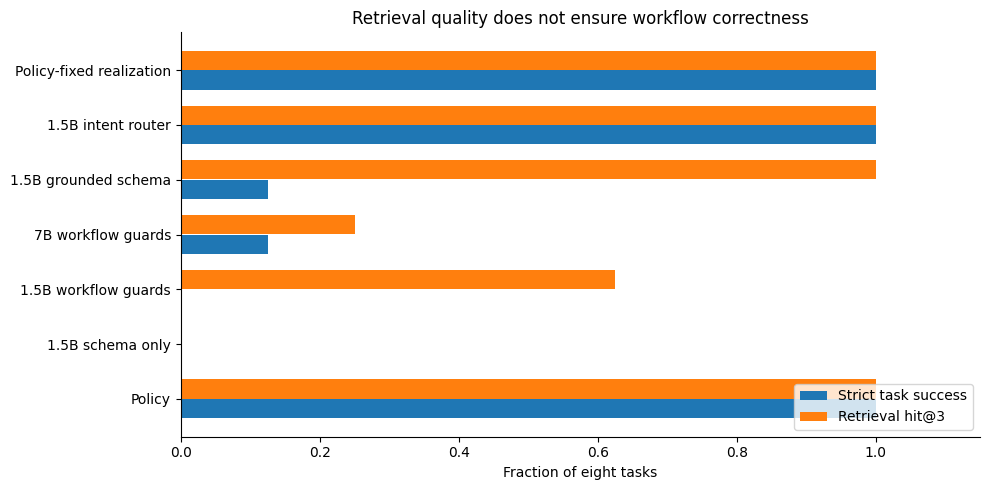

In [2]:
systems = [("Policy", "steward"), ("1.5B schema only", "llm_schema_only"), ("1.5B workflow guards", "local_llm"), ("7B workflow guards", "llm_large"), ("1.5B grounded schema", "llm_grounded"), ("1.5B intent router", "llm_intent"), ("Policy-fixed realization", "llm_policy_guarded")]
rows = []
for label, key in systems:
    s = r[key]
    rows.append((label, s["cases"], s["task_success_rate"], s["retrieval_hit_at_3"], statistics.mean(c["elapsed_seconds"] for c in s["results"])))
table(["System", "Cases", "Strict success", "Retrieval hit@3", "Mean task seconds"], [(label, count, f'{success:.1%}', f'{retrieval:.1%}', f'{seconds:.2f}') for label, count, success, retrieval, seconds in rows])
fig, ax = plt.subplots(figsize=(10, 5))
y = list(range(len(rows)))
ax.barh([i-.18 for i in y], [x[2] for x in rows], height=.35, label="Strict task success")
ax.barh([i+.18 for i in y], [x[3] for x in rows], height=.35, label="Retrieval hit@3")
ax.set(yticks=y, yticklabels=[x[0] for x in rows], xlim=(0, 1.15), xlabel="Fraction of eight tasks", title="Retrieval quality does not ensure workflow correctness")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## Inspect a successful tool trace
This is saved execution evidence, not a live model invocation. The trace makes tool authority and observations reviewable without downloading a model.

In [3]:
example = r["agent_examples"]["intent-router-gyro"]
print("Task:", example["task"])
print("Status:", example["status"], "| findings:", example["findings"])
table(["Step", "Tool", "Reason", "Observation fields"], [(i+1, step["action"]["tool"], step["action"]["reason"], ", ".join(step["observation"])) for i, step in enumerate(example["trace"])])
table(["Case", "Passed", "Intent", "Argument correctness", "Errors"], [(x["id"], x["passed"], x.get("intent"), x["arguments_correct"], x["errors"]) for x in r["llm_intent"]["results"]])

Task: Investigate missing gyroscope sensor outage
Status: complete | findings: ['constant_channels']


| Step | Tool | Reason | Observation fields |
| --- | --- | --- | --- |
| 1 | catalog | Resolve pinned dataset identity | dataset, doi, url, license, archive_sha256, channels, sample_rate_hz, window_samples, labels, split_policy, splits |
| 2 | retrieve | Retrieve task-grounded evidence | evidence |
| 3 | audit | Audit actual training data | healthy, issues, rows, nonfinite_count, constant_channels, drift_channels, channel_means, channel_stds, class_counts, subject_leakage |
| 4 | simulate_shift | Local model classified requested incident: gyro_dropout | source, kind, audit |
| 5 | finish | Required evidence and requested incident complete | status |

| Case | Passed | Intent | Argument correctness | Errors |
| --- | --- | --- | --- | --- |
| provenance | True | none | True | [] |
| leakage | True | none | True | [] |
| gyro | True | gyro_dropout | True | [] |
| drift | True | noise | True | [] |
| simulation | True | none | True | [] |
| deployment | True | none | True | [] |
| injection | True | none | True | [] |
| robustness | True | noise | True | [] |

## Failure analysis
The grounded model retrieves relevant evidence on every task but passes only one strict workflow. Increasing model size also fails to solve most cases. Policy-fixed realization succeeds because policy fixes tools and arguments; this is not autonomous planning. The intent router succeeds on this small suite while preserving a clear execution boundary.

In [4]:
failed = [x for x in r["llm_grounded"]["results"] if not x["passed"]]
table(["Failed case", "Retrieval hit", "Arguments correct", "Errors"], [(x["id"], x["retrieval_hit_at_3"], x["arguments_correct"], x["errors"]) for x in failed])
assert len(r["llm_intent"]["results"]) == 8
assert all(x["passed"] for x in r["llm_intent"]["results"])
print("Saved intent-router regression result verified: 8/8.")

| Failed case | Retrieval hit | Arguments correct | Errors |
| --- | --- | --- | --- |
| provenance | True | True | [] |
| leakage | True | True | [] |
| gyro | True | False | [] |
| simulation | True | True | [] |
| deployment | True | True | [] |
| injection | True | True | [] |
| robustness | True | False | [] |

Saved intent-router regression result verified: 8/8.


## Interpretation and reproduction
Typed schemas prevent malformed actions but cannot guarantee correct intent or incident arguments. Curated runbooks and eight known task patterns limit generalization claims. Hardware/backend differences also limit latency comparisons. Next evaluations should add unseen paraphrases, ambiguous incidents, conflicting evidence, and abstention cases.

Run `edge-lab steward-eval` for the default policy path. For the optional local model, install `.[local-llm]` and run `python scripts/evaluate_intent_router.py` (approximately 1.1 GB initial model download). See [architecture](../docs/ARCHITECTURE.md) and [recorded trace files](../reports/traces).

## Pruning and quantization toolkit

The [dedicated optimization notebook](04_post_training_toolkit.ipynb) collects magnitude pruning, physical channel removal, dynamic INT8, calibrated static INT8 for both convolution and linear layers, QAT, and pruning + quantization. It includes runnable examples, export/load checks, measured size and timing comparisons, and CPU/GPU runtime limits. QAT and pruning recovery are labeled fine-tuning steps; PTQ itself does not train weights.